# The symmetric 0-pi qubit (notes Appendix B.2)

Each step follows the notes; equation labels are given in comments.

In [1]:
import sympy as sym
import circuit_quantization as cq
from circuit_quantization import Branch, Circuit, Loops, quantize

sym.init_printing()
F, H, W = cq.ghz_to_farad, cq.ghz_to_henry, cq.phase_to_weber

In [17]:
CJ, C, L, EJ = sym.symbols("C_J C L E_J", positive=True)
circuit = Circuit([
    Branch("J1", 1, 2, C=CJ, EJ=EJ),
    Branch("J2", 3, 4, C=CJ, EJ=EJ),
    Branch("L1", 2, 3, L=L),
    Branch("L2", 4, 1, L=L),
    Branch("C1", 1, 3, C=C),
    Branch("C2", 2, 4, C=C),
], ground=5)  # floating: ground carries no branch
cycles = {  # eq:zp_G
    "ring": {"J1": 1, "J2": 1, "L1": 1, "L2": 1},
    "t1": {"J1": 1, "L1": 1, "C1": -1},
    "t2": {"J2": 1, "L1": 1, "C2": -1},
}
loops = Loops(circuit, cycles, {"t1": 0, "t2": 0})
Z = sym.Matrix([[-1, -1, 1, 1], [1, 1, 1, 1], [-1, 1, -1, 1], [1, -1, -1, 1]]) / 2  # eq:zp_Z
res = quantize(circuit, loops, Z, ("e", "c", "h", "cy"), simplify=True)
res

-2*E_J*cos(varphi_1)*cos(varphi_2) + e**2*(n_2 - n_g2)**2/(h*(C + C_J)) + Phi_0**2*varphi_1**2/(4*pi**2*L*h) + Phi_0**2*varphi_3**2/(4*pi**2*L*h) + Phi_0*Phi_ring*(varphi_1 - varphi_3)/(2*pi*L*h) + e**2*n_1**2/(C_J*h) + e**2*n_3**2/(C*h)

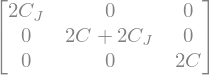

In [3]:
res.coords.C_tilde

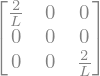

In [4]:
res.coords.Lstar_tilde

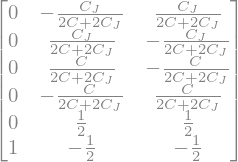

In [5]:
res.B